In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_ref = os.path.join(pth_data, 'ref', 'AnimalTFDBv4')
pth_fig = os.path.join(pth, 'figures', 'mesencoder', 'bifurcation')
pth_out = os.path.join(pth_data, 'results', 'regulation')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'mesencoder.h5ad'))
adata1 = sc.read_h5ad(os.path.join(pth_in, 'bifurcation.h5ad'))
adata1

AnnData object with n_obs × n_vars = 2811 × 338
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones', 't_bin', 'correlation'
    uns: 'celltype_colors', 'graph', 'milestones_colors', 'neighbors', 'pseudotime_list', 'seg_colors'
    obsm: 'X_R', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_spectrum', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'
    obsp: 'connectivities', 'distances'

In [4]:
# transcription factors
fn = os.path.join(pth_ref, 'Mus_musculus_TF')
tf = pd.read_csv(fn, sep = '\t').Symbol
tf = tf.loc[tf.isin(adata1.var_names)]
X = adata1[:, tf].X.toarray()
msk = (X.mean(axis = 0) > 1e-5)
tf = tf.loc[msk].values

In [5]:
# X: TF expression
X = adata1[:, tf].X.toarray()
X = StandardScaler().fit_transform(X)

# y: mutual negative correlation
y = adata1.obs.correlation.values.reshape(-1, 1)
y = StandardScaler().fit_transform(y).flatten()

# linear regression (y ~ X)
reg = LinearRegression().fit(X, y)

# TF coefficients (beta)
beta = pd.Series(reg.coef_, index = tf)
beta = beta.sort_values(ascending = False); beta.name = 'coef'
beta.to_csv(os.path.join(pth_out, 'bifurcation.csv')); beta

Mesp1     0.171900
Mixl1     0.147399
Pou5f1    0.123463
T         0.117252
Lhx1      0.090925
            ...   
Cdx2     -0.061206
Cdx4     -0.068643
Prdm6    -0.073225
Foxf1    -0.104183
Etv2     -0.169727
Name: coef, Length: 81, dtype: float32

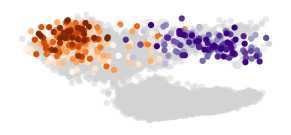

In [6]:
cmap_dict = {'Mesp1' : 'Oranges', 'Etv2' : 'Purples'}
vlim = {'Mesp1' : [4.25, 'p95'], 'Etv2' : [2, 'p90']}

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0], size = 80,
                alpha = .5, frameon = False, show = False, ax = ax)
for g, (vmin, vmax) in vlim.items():
    sc.pl.embedding(adata1[adata1[:, g].X.toarray() > vmin],
                    'X_mesencoder', dimensions = [1, 0],
                    size = 80, color = g, cmap = cmap_dict[g],
                    vmin = vmin, vmax = vmax, colorbar_loc = None,
                    frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

fn = os.path.join(pth_fig, 'regulation.pdf')
plt.savefig(fn, bbox_inches = 'tight')